# RQ1 — Thời điểm đăng video có ảnh hưởng đến khả năng lọt Top Trending? (YouTube, VN)

**Nhóm 6 · ADY201m · Report 4 (Modeling & Validation)**

**Câu hỏi nghiên cứu (RQ1).** Video đăng trong *khung giờ hành chính* (thứ Hai–thứ Sáu, 8h–17h giờ VN) hay *khung giờ nghỉ ngơi* (buổi tối, ban đêm, cuối tuần) có khả năng xuất hiện trên bảng Trending cao hơn?

- **H₀:** Khả năng xuất hiện trên Trending **không khác nhau** giữa hai khung giờ.
- **H₁:** Có khác biệt có ý nghĩa thống kê (α = 0,05, kiểm định hai phía).

**Dữ liệu:** `data/processed/rq1_youtube_cohort_VN.csv` (rolling cohort, 9 batch) + `youtube_cohort_registry_VN.csv` (lấy `category_id`).

**Cách chạy:** đặt file trong thư mục `notebooks/`, chạy lần lượt từ trên xuống. Chỉ cần `pandas, numpy, scipy, scikit-learn, matplotlib`.

**Nội dung:** (1) kiểm tra chất lượng nhãn → (2) kiểm định thống kê có phân tầng theo batch → (3) phân tích độ nhạy → (4) Mô hình 1: Logistic Regression → (5) Mô hình 2: Random Forest → (6) kết luận.

In [1]:
import warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
SEED = 42
ALPHA = 0.05

candidates = [Path("../data/processed"), Path("data/processed")]
DATA = next(p for p in candidates if (p / "rq1_youtube_cohort_VN.csv").exists())

cohort = pd.read_csv(DATA / "rq1_youtube_cohort_VN.csv", encoding="utf-8-sig")
registry = pd.read_csv(DATA / "youtube_cohort_registry_VN.csv", encoding="utf-8-sig",
                       usecols=["video_id", "category_id"]).drop_duplicates("video_id")
df = cohort.merge(registry, on="video_id", how="left")
assert len(df) == len(cohort) and df.video_id.is_unique
print(f"Đọc {len(df):,} video, {df.batch_id.nunique()} batch, "
      f"{df.category_id.nunique()} category (thiếu category: {df.category_id.isna().sum()}).")

Đọc 11,531 video, 9 batch, 15 category (thiếu category: 0).


## 1. Kiểm tra chất lượng nhãn (Data audit)

Nhãn `chart_label_status` có 3 giá trị: `OBSERVED_POSITIVE` (đã thấy trên chart), `OBSERVED_NEGATIVE_FULL_COVERAGE` (không thấy dù chart monitor phủ đủ 24h) và `UNKNOWN_INCOMPLETE_COVERAGE` (không thấy nhưng monitor bị gián đoạn nên **không biết** video có lên chart hay không).

Cần xem nhãn phân bố thế nào **theo batch**, vì nếu hai nhóm nhãn đến từ các batch khác nhau thì so sánh trực tiếp sẽ bị lẫn hiệu ứng batch.

In [2]:
audit = pd.crosstab(df.batch_id, df.chart_label_status)
audit["n_video"] = audit.sum(axis=1)
audit["coverage_TB"] = df.groupby("batch_id").chart_coverage_ratio.mean().round(2)
print(audit.to_string())

neg = df[df.chart_label_status == "OBSERVED_NEGATIVE_FULL_COVERAGE"]
pos = df[df.chart_label_status == "OBSERVED_POSITIVE"]
big = neg.batch_id.value_counts().idxmax()
print(f"\n{neg.batch_id.eq(big).mean():.1%} video 'âm tính đầy đủ' đến từ MỘT batch ({big}).")
print(f"Nhưng batch đó chỉ chứa {pos.batch_id.eq(big).sum()}/{len(pos)} video dương tính.")
print(f"{df.chart_label_status.eq('UNKNOWN_INCOMPLETE_COVERAGE').mean():.1%} video chưa biết nhãn (UNKNOWN).")

chart_label_status         OBSERVED_NEGATIVE_FULL_COVERAGE  OBSERVED_POSITIVE  UNKNOWN_INCOMPLETE_COVERAGE  n_video  coverage_TB
batch_id                                                                                                                        
VN_20261012_150617_441858                                0                  0                           10       10         0.67
VN_20261012_171816_750723                                0                  0                           20       20         0.71
VN_20261014_010155_264576                                0                 11                          989     1000         0.83
VN_20261015_010214_054091                                0                 15                          985     1000         0.67
VN_20261017_092001_115683                             1998                  2                            0     2000         1.00
VN_20261018_010519_873424                                0                  0                    

**Nhận xét.** Gần như toàn bộ nhãn âm tính "chắc chắn" nằm trong một batch, còn video dương tính nằm ở các batch khác. Vì vậy **không được** chỉ lấy tập có nhãn rõ ràng (dương + âm đầy đủ) rồi so sánh hai khung giờ: sự khác biệt giữa batch sẽ lẫn vào kết quả.

**Cách xử lý dùng trong notebook này.**
- Biến kết quả: `pos = 1` nếu video **đã được quan sát** trên Trending trong cửa sổ theo dõi, ngược lại `pos = 0`. Đây là ước lượng *cận dưới* của xác suất lọt Trending (có thể bỏ sót video lên chart lúc monitor tắt).
- Dùng **toàn bộ 11.531 video** và **phân tầng theo batch** (kiểm định Cochran–Mantel–Haenszel); đưa `chart_coverage_ratio` vào mô hình để kiểm soát phần bỏ sót do monitor.

In [3]:
# --- Xây dựng biến ---
df["pos"] = (df.chart_label_status == "OBSERVED_POSITIVE").astype(int)

# Giờ/ngày địa phương tính độc lập từ thời điểm đăng (UTC) để không phụ thuộc cột có sẵn
t_local = pd.to_datetime(df.published_at_utc, utc=True, format="mixed").dt.tz_convert("Asia/Ho_Chi_Minh")
df["hour"] = t_local.dt.hour
df["dow"] = t_local.dt.dayofweek                               # Thứ Hai = 0
df["weekend"] = (df.dow >= 5).astype(int)                      # Thứ Bảy, Chủ Nhật
# Định nghĩa của nhóm (src/processing/build_rq1_dataset.py): Thứ Hai–Thứ Sáu, 8:00–16:59
df["office"] = ((df.dow < 5) & df.hour.between(8, 16)).astype(int)
df["office_9_17"] = df.hour.between(9, 16).astype(int)         # định nghĩa 9–17h mọi ngày (script R cũ)

mismatch = (df.hour != df.upload_hour_local).sum()
agree = (df.office == (df.upload_period == "OFFICE_HOURS")).mean()
print(f"Giờ tính lại khớp cột upload_hour_local: {mismatch == 0}  |  khớp upload_period: {agree:.1%}")

df["log_age"] = np.log1p(df.video_age_at_t0_hours)
df["log_views"] = np.log1p(df.t0_view_count)
df["coverage"] = df.chart_coverage_ratio
df["hour_sin"] = np.sin(2 * np.pi * df.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df.hour / 24)

print(f"\nTổng video: {len(df):,} | video quan sát được trên Trending: {df.pos.sum()} ({df.pos.mean():.2%})")
print(f"Hành chính (T2–T6, 8–17h): {df.office.sum():,} video ({df.office.mean():.1%}) | Ngoài giờ (tối, đêm, cuối tuần): {(1-df.office).sum():,}")

Giờ tính lại khớp cột upload_hour_local: True  |  khớp upload_period: 100.0%

Tổng video: 11,531 | video quan sát được trên Trending: 46 (0.40%)
Hành chính (T2–T6, 8–17h): 2,448 video (21.2%) | Ngoài giờ (tối, đêm, cuối tuần): 9,083


## 2. Kiểm định thống kê cho RQ1

Hai thước đo: (a) kiểm định thô (2×2, Chi-square/Fisher); (b) **kiểm định phân tầng theo batch** (Cochran–Mantel–Haenszel, OR gộp Mantel–Haenszel với khoảng tin cậy Robins–Breslow–Greenland). Kết quả (b) là kết quả chính.

In [4]:
def table_2x2(d, exp="office", out="pos"):
    a = int(((d[exp] == 1) & (d[out] == 1)).sum()); b = int(((d[exp] == 1) & (d[out] == 0)).sum())
    c = int(((d[exp] == 0) & (d[out] == 1)).sum()); e = int(((d[exp] == 0) & (d[out] == 0)).sum())
    return a, b, c, e

def woolf_or(a, b, c, d):
    # OR và 95% CI (Woolf, hiệu chỉnh 0,5 nếu có ô bằng 0)
    if min(a, b, c, d) == 0:
        a, b, c, d = a + .5, b + .5, c + .5, d + .5
    o = a * d / (b * c); se = math.sqrt(1/a + 1/b + 1/c + 1/d)
    return o, o * math.exp(-1.96 * se), o * math.exp(1.96 * se)

def cmh(d, exp="office", strata="batch_id", out="pos"):
    R = S = P = Q = PR = PSQR = QS = 0.0
    E = V = A = 0.0
    for _, g in d.groupby(strata):
        a, b, c, e = table_2x2(g, exp, out); n = a + b + c + e
        if n < 2:
            continue
        R += a*e/n; S += b*c/n
        P_i, Q_i = (a+e)/n, (b+c)/n
        PR += P_i*(a*e/n); PSQR += P_i*(b*c/n) + Q_i*(a*e/n); QS += Q_i*(b*c/n)
        r1, c1 = a+b, a+c
        E += r1*c1/n; A += a
        V += r1*(n-r1)*c1*(n-c1)/(n**2*(n-1))
    or_mh = R / S
    se = math.sqrt(PR/(2*R**2) + PSQR/(2*R*S) + QS/(2*S**2))
    chi2 = (abs(A - E) - 0.5)**2 / V
    return or_mh, or_mh*math.exp(-1.96*se), or_mh*math.exp(1.96*se), chi2, 1 - stats.chi2.cdf(chi2, 1)

def analyse(d, exp, label):
    a, b, c, e = table_2x2(d, exp)
    o, lo, hi = woolf_or(a, b, c, e)
    p_fisher = stats.fisher_exact([[a, b], [c, e]])[1]
    o_mh, lo_mh, hi_mh, chi2, p_mh = cmh(d, exp)
    return {"Định nghĩa": label, "n nhóm=1": a+b, "n nhóm=0": c+e, "dương/nhóm=1": a, "dương/nhóm=0": c,
            "tỷ lệ nhóm=1 (%)": 100*a/(a+b), "tỷ lệ nhóm=0 (%)": 100*c/(c+e),
            "OR thô": o, "Fisher p": p_fisher, "OR MH": o_mh, "MH 95% CI": f"{lo_mh:.2f}–{hi_mh:.2f}", "CMH p": p_mh}

main = analyse(df, "office", "Hành chính T2–T6 8–17h (=1) vs còn lại (=0)")
for k, v in main.items():
    print(f"{k:>18}: {v:.4f}" if isinstance(v, float) else f"{k:>18}: {v}")

a, b, c, e = table_2x2(df)
print("\nBảng 2×2 (hàng: hành chính / ngoài giờ; cột: có trên Trending / không):")
print(pd.DataFrame([[a, b], [c, e]], index=["Hành chính", "Ngoài giờ"], columns=["Trending", "Không"]).to_string())
P_MAIN = main["CMH p"]
OR_MAIN = main["OR MH"]; CI_MAIN = main["MH 95% CI"]

        Định nghĩa: Hành chính T2–T6 8–17h (=1) vs còn lại (=0)
          n nhóm=1: 2448
          n nhóm=0: 9083
      dương/nhóm=1: 9
      dương/nhóm=0: 37
  tỷ lệ nhóm=1 (%): 0.3676
  tỷ lệ nhóm=0 (%): 0.4074
            OR thô: 0.9022
          Fisher p: 1.0000
             OR MH: 0.7961
         MH 95% CI: 0.38–1.66
             CMH p: 0.6668

Bảng 2×2 (hàng: hành chính / ngoài giờ; cột: có trên Trending / không):
            Trending  Không
Hành chính         9   2439
Ngoài giờ         37   9046


### Sức mạnh thống kê (power)

Chỉ có **46 video dương tính**, nên cần biết kiểm định này phát hiện được mức khác biệt nhỏ nhất là bao nhiêu. Dưới đây là OR nhỏ nhất đạt power 80% (α = 0,05) với cỡ mẫu và tỷ lệ nền hiện có.

In [5]:
def mde_or(n1, n0, p0, alpha=0.05, power=0.80, direction="up"):
    za, zb = stats.norm.ppf(1 - alpha/2), stats.norm.ppf(power)
    def gap(or_):
        p1 = or_*p0 / (1 - p0 + or_*p0)
        pbar = (n1*p1 + n0*p0) / (n1 + n0)
        se0 = math.sqrt(pbar*(1-pbar)*(1/n1 + 1/n0))
        se1 = math.sqrt(p1*(1-p1)/n1 + p0*(1-p0)/n0)
        return (abs(p1 - p0) - za*se0) / se1 - zb
    return brentq(gap, 1.0001, 100) if direction == "up" else brentq(gap, 0.0001, 0.9999)

n1, n0 = int(df.office.sum()), int((1 - df.office).sum())
p0 = df.loc[df.office == 0, "pos"].mean()
mde_up, mde_dn = mde_or(n1, n0, p0), mde_or(n1, n0, p0, direction="down")
print(f"Tỷ lệ nền (ngoài giờ): {p0:.2%};  n hành chính = {n1:,},  n ngoài giờ = {n0:,}")
print(f"OR nhỏ nhất phát hiện được với power 80%:  tăng ≥ {mde_up:.2f} lần  hoặc  giảm ≤ {mde_dn:.2f} lần")
print("=> Kiểm định này chỉ đủ nhạy với khác biệt LỚN; khác biệt nhỏ (OR gần 1) sẽ không bị phát hiện.")

Tỷ lệ nền (ngoài giờ): 0.41%;  n hành chính = 2,448,  n ngoài giờ = 9,083
OR nhỏ nhất phát hiện được với power 80%:  tăng ≥ 2.21 lần  hoặc  giảm ≤ 0.18 lần
=> Kiểm định này chỉ đủ nhạy với khác biệt LỚN; khác biệt nhỏ (OR gần 1) sẽ không bị phát hiện.


## 3. Phân tích độ nhạy

Kết luận có phụ thuộc vào cách định nghĩa "giờ hành chính" hoặc cách gán nhãn không? Kế hoạch (`finalize_analysis_plan.md`) ghi 8h–17h, còn code dùng 9h–17h; kế hoạch cũng nhắc "giờ vàng" 17h–23h và cuối tuần.

In [6]:
rows = []
rows.append(analyse(df, "office", "A. Hành chính T2–T6 8–17h vs còn lại (CHÍNH)"))
rows.append(analyse(df, "office_9_17", "B. Hành chính 9–17h mọi ngày vs còn lại"))

d = df[(df.dow < 5) & (df.hour >= 8) & (df.hour < 23)]
rows.append(analyse(d, "office", "C. Ngày thường: 8–17h vs buổi tối 17–23h"))

rows.append(analyse(df, "weekend", "D. Cuối tuần (=1) vs ngày thường (=0) [khám phá]"))

rows.append(analyse(df[df.coverage >= 0.70], "office", "E. Chỉ video có coverage ≥ 0,70 (như A)"))
rows.append(analyse(df[df.video_age_at_t0_hours <= 24], "office", "F. Chỉ video ≤ 24h tuổi lúc T0 (như A)"))

sens = pd.DataFrame(rows)
show = sens[["Định nghĩa", "n nhóm=1", "n nhóm=0", "dương/nhóm=1", "dương/nhóm=0",
             "tỷ lệ nhóm=1 (%)", "tỷ lệ nhóm=0 (%)", "OR MH", "MH 95% CI", "CMH p"]].copy()
for col in ["tỷ lệ nhóm=1 (%)", "tỷ lệ nhóm=0 (%)", "OR MH"]:
    show[col] = show[col].round(2)
show["CMH p"] = show["CMH p"].round(3)
print(show.to_string(index=False))
print(f"\nNgưỡng Bonferroni cho 6 biến thể: α/6 = {ALPHA/6:.4f}. Biến thể D được thêm sau khi xem dữ liệu nên chỉ mang tính khám phá.")

                                      Định nghĩa  n nhóm=1  n nhóm=0  dương/nhóm=1  dương/nhóm=0  tỷ lệ nhóm=1 (%)  tỷ lệ nhóm=0 (%)  OR MH MH 95% CI  CMH p
    A. Hành chính T2–T6 8–17h vs còn lại (CHÍNH)      2448      9083             9            37              0.37              0.41   0.80 0.38–1.66  0.667
         B. Hành chính 9–17h mọi ngày vs còn lại      3154      8377            14            32              0.44              0.38   1.21 0.65–2.27  0.667
        C. Ngày thường: 8–17h vs buổi tối 17–23h      2448      3157             9            18              0.37              0.57   0.65 0.29–1.46  0.395
D. Cuối tuần (=1) vs ngày thường (=0) [khám phá]      3060      8471            17            29              0.56              0.34   3.29 1.75–6.19  0.000
         E. Chỉ video có coverage ≥ 0,70 (như A)       979      4029             2            11              0.20              0.27   0.63 0.14–2.86  0.786
          F. Chỉ video ≤ 24h tuổi lúc T0 (như A)       854

### Phân bố theo từng khung 3 giờ

Xem tỷ lệ xuất hiện trên Trending theo từng khung giờ (khoảng tin cậy Wilson 95%) để thấy có "giờ vàng" cụ thể nào không.

        sum  count  rate_%    lo    hi
block                                 
00–03h    0   1222    0.00  0.00  0.31
03–06h    2   1053    0.19  0.05  0.69
06–09h    0   1239    0.00  0.00  0.31
09–12h    5   1138    0.44  0.19  1.02
12–15h    2   1073    0.19  0.05  0.68
15–18h   13   1549    0.84  0.49  1.43
18–21h   18   2566    0.70  0.44  1.11
21–24h    6   1691    0.35  0.16  0.77

Chi-square giữa 8 khung giờ (thô, chưa phân tầng): χ²=25.83, df=7, p=0.001


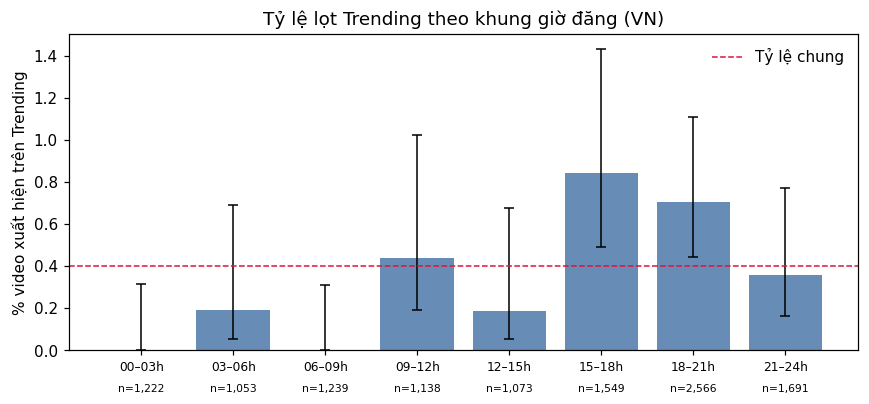

In [7]:
def wilson(k, n, z=1.96):
    if n == 0:
        return 0, 0
    p = k / n; den = 1 + z**2 / n
    ctr = (p + z**2 / (2*n)) / den
    half = z * math.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return ctr - half, ctr + half

df["block"] = pd.cut(df.hour, bins=range(0, 25, 3), right=False,
                     labels=[f"{h:02d}–{h+3:02d}h" for h in range(0, 24, 3)])
blk = df.groupby("block", observed=True).pos.agg(["sum", "count"])
blk["rate_%"] = 100 * blk["sum"] / blk["count"]
ci = [wilson(int(k), int(n)) for k, n in zip(blk["sum"], blk["count"])]
blk["lo"] = [100*c[0] for c in ci]; blk["hi"] = [100*c[1] for c in ci]
print(blk.round(2).to_string())

chi2_b, p_b, _, _ = stats.chi2_contingency(np.c_[blk["sum"], blk["count"] - blk["sum"]], correction=False)
print(f"\nChi-square giữa 8 khung giờ (thô, chưa phân tầng): χ²={chi2_b:.2f}, df=7, p={p_b:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(blk))
ax.bar(x, blk["rate_%"], color="#4C78A8", alpha=.85)
ax.errorbar(x, blk["rate_%"], yerr=[blk["rate_%"] - blk["lo"], blk["hi"] - blk["rate_%"]],
            fmt="none", ecolor="black", capsize=3, lw=1)
ax.axhline(100 * df.pos.mean(), color="crimson", ls="--", lw=1, label="Tỷ lệ chung")
ax.set_xticks(x); ax.set_xticklabels(blk.index, rotation=0, fontsize=8)
for xi, n in zip(x, blk["count"]):
    ax.text(xi, -0.13*ax.get_ylim()[1], f"n={n:,}", ha="center", fontsize=7)
ax.set_ylabel("% video xuất hiện trên Trending"); ax.set_title("Tỷ lệ lọt Trending theo khung giờ đăng (VN)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### Kiểm chứng chéo theo thời gian cho các mẫu hình khám phá

Biểu đồ trên cho thấy các video lọt Trending tập trung vào buổi chiều–tối, và biến thể D (cuối tuần) có vẻ khác biệt. Đây là các mẫu hình **tìm ra sau khi nhìn dữ liệu**, nên cần kiểm tra lại trên dữ liệu mới. Cách làm: chia cohort theo thời gian — nửa **khám phá** (batch 14–15/10) và nửa **kiểm chứng** (các batch sau đó). Khung giờ "đỉnh" được chọn **chỉ từ nửa khám phá**, rồi kiểm định trên nửa kiểm chứng.

In [8]:
CUT = "VN_20261015_999999"
disc, valid = df[df.batch_id <= CUT].copy(), df[df.batch_id > CUT].copy()
print(f"Khám phá: {len(disc):,} video, {int(disc.pos.sum())} dương tính | Kiểm chứng: {len(valid):,} video, {int(valid.pos.sum())} dương tính")

bd = disc.groupby("block", observed=True).pos.agg(["sum", "count"])
bd["rate_%"] = 100 * bd["sum"] / bd["count"]
peak = bd["rate_%"].idxmax()
print(f"Khung 3 giờ có tỷ lệ cao nhất ở nửa khám phá: {peak}")

rows = []
for name, part in [("Khám phá", disc), ("Kiểm chứng", valid)]:
    r1 = analyse(part.assign(peak=(part.block == peak).astype(int)), "peak", f"{name}: khung {peak} vs còn lại")
    r2 = analyse(part, "weekend", f"{name}: cuối tuần vs ngày thường")
    rows += [r1, r2]
rep_tab = pd.DataFrame(rows)[["Định nghĩa", "n nhóm=1", "dương/nhóm=1", "dương/nhóm=0", "tỷ lệ nhóm=1 (%)",
                              "tỷ lệ nhóm=0 (%)", "OR MH", "MH 95% CI", "CMH p"]]
for col in ["tỷ lệ nhóm=1 (%)", "tỷ lệ nhóm=0 (%)", "OR MH"]:
    rep_tab[col] = rep_tab[col].round(2)
rep_tab["CMH p"] = rep_tab["CMH p"].round(3)
print(rep_tab.to_string(index=False))
REP_PEAK = peak
REP_VALID_PEAK_P = rows[2]["CMH p"]; REP_VALID_PEAK_OR = rows[2]["OR MH"]
REP_VALID_WE_P = rows[3]["CMH p"]; REP_VALID_WE_OR = rows[3]["OR MH"]

Khám phá: 2,030 video, 26 dương tính | Kiểm chứng: 9,501 video, 20 dương tính
Khung 3 giờ có tỷ lệ cao nhất ở nửa khám phá: 15–18h
                          Định nghĩa  n nhóm=1  dương/nhóm=1  dương/nhóm=0  tỷ lệ nhóm=1 (%)  tỷ lệ nhóm=0 (%)  OR MH  MH 95% CI  CMH p
   Khám phá: khung 15–18h vs còn lại       295             9            17              3.05              0.98   3.11  1.37–7.06  0.010
  Khám phá: cuối tuần vs ngày thường       410            11            15              2.68              0.93   3.07  1.39–6.78  0.008
 Kiểm chứng: khung 15–18h vs còn lại      1254             4            16              0.32              0.19   1.47  0.49–4.43  0.710
Kiểm chứng: cuối tuần vs ngày thường      2650             6            14              0.23              0.20   3.77 1.34–10.61  0.022


## 4. Mô hình 1 — Logistic Regression (kiểm soát nhiễu)

Mục tiêu: ước lượng ảnh hưởng của khung giờ **sau khi kiểm soát** tuổi video, lượt xem tại T0, thể loại, batch và độ phủ chart monitor.

- Biến phụ thuộc: `pos` (đã quan sát trên Trending).
- Biến quan tâm: `office` (T2–T6, 8–17h) và `weekend`; nhóm tham chiếu là *ngày thường ngoài 8–17h* (tối/đêm).
- Biến kiểm soát: `log_age`, `log_views`, `coverage`, `category_id` (one-hot), `batch_id` (one-hot).
- Hồi quy có phạt L2 (C = 10) vì một số batch không có video dương tính; **khoảng tin cậy lấy bằng bootstrap** (300 lần).

In [9]:
CONT = ["log_age", "log_views", "coverage"]
cat_d = pd.get_dummies(df.category_id.astype(int).astype(str), prefix="cat").astype(int)
bat_d = pd.get_dummies(df.batch_id, prefix="batch").astype(int)
X_ctrl = pd.concat([df[CONT], cat_d, bat_d], axis=1)
X_all = pd.concat([df[["office", "weekend", "hour_sin", "hour_cos"]], X_ctrl], axis=1)
y = df.pos.values
TIME_COLS = ["office", "hour_sin", "hour_cos", "weekend"]
BASE_COLS = list(X_ctrl.columns)

def make_pipe(kind, cols):
    cont_in = [c for c in CONT if c in cols]
    pre = ColumnTransformer([("num", StandardScaler(), cont_in)], remainder="passthrough")
    if kind == "logit":
        mdl = LogisticRegression(C=10, max_iter=3000)
    else:
        mdl = RandomForestClassifier(n_estimators=200, min_samples_leaf=10, max_features="sqrt",
                                     class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    return Pipeline([("pre", pre), ("mdl", mdl)])

INF_COLS = ["office", "weekend"] + BASE_COLS
Xi = X_all[INF_COLS]
fit = make_pipe("logit", INF_COLS).fit(Xi, y)
names = [c for c in INF_COLS if c in CONT] + [c for c in INF_COLS if c not in CONT]   # thứ tự sau ColumnTransformer
coef = pd.Series(fit.named_steps["mdl"].coef_[0], index=names)

# Bootstrap cho OR của 'office' và 'weekend'
rng = np.random.default_rng(SEED)
boot = {"office": [], "weekend": []}
for _ in range(300):
    idx = rng.integers(0, len(df), len(df))
    if y[idx].sum() < 10:
        continue
    m = make_pipe("logit", INF_COLS).fit(Xi.iloc[idx], y[idx])
    cf = pd.Series(m.named_steps["mdl"].coef_[0], index=names)
    boot["office"].append(cf["office"]); boot["weekend"].append(cf["weekend"])

res = []
for v, lab in [("office", "Hành chính T2–T6 8–17h (so với ngày thường ngoài giờ)"), ("weekend", "Cuối tuần (so với ngày thường ngoài giờ)")]:
    lo, hi = np.percentile(boot[v], [2.5, 97.5])
    res.append({"Biến": lab, "OR": math.exp(coef[v]), "95% CI (bootstrap)": f"{math.exp(lo):.2f}–{math.exp(hi):.2f}",
                "CI chứa 1?": "Có" if lo <= 0 <= hi else "Không"})
for v, lab in [("log_age", "log tuổi video lúc T0 (+1 SD)"), ("log_views", "log lượt xem T0 (+1 SD)"),
               ("coverage", "Độ phủ chart monitor (+1 SD)")]:
    res.append({"Biến": lab, "OR": math.exp(coef[v]), "95% CI (bootstrap)": "—", "CI chứa 1?": "—"})
logit_tab = pd.DataFrame(res)
logit_tab["OR"] = logit_tab["OR"].round(2)
print(logit_tab.to_string(index=False))
OR_LOGIT = math.exp(coef["office"])
CI_LOGIT = logit_tab.loc[0, "95% CI (bootstrap)"]
LOGIT_CI_HAS_1 = logit_tab.loc[0, "CI chứa 1?"]

                                                 Biến   OR 95% CI (bootstrap) CI chứa 1?
Hành chính T2–T6 8–17h (so với ngày thường ngoài giờ) 0.80          0.38–2.11         Có
             Cuối tuần (so với ngày thường ngoài giờ) 1.93          1.07–4.81      Không
                        log tuổi video lúc T0 (+1 SD) 0.70                  —          —
                              log lượt xem T0 (+1 SD) 3.52                  —          —
                         Độ phủ chart monitor (+1 SD) 0.63                  —          —


## 5. Mô hình 2 — Random Forest và so sánh hai mô hình

Random Forest bắt được quan hệ phi tuyến và tương tác (ví dụ khung giờ × thể loại). Câu hỏi kiểm định ở đây mang tính **dự báo**: *thêm thông tin thời điểm đăng có giúp dự đoán video nào lên Trending tốt hơn không?*

- Hai bộ biến cho mỗi mô hình: **Base** (không có biến thời gian) và **Base + Thời gian** (`office`, `hour_sin`, `hour_cos`, `weekend`).
- Đánh giá bằng Repeated Stratified 5-fold × 3 lần. Vì chỉ ~0,4% video là dương tính nên **không dùng Accuracy** (dự đoán toàn "không" đã đạt ~99,6%); dùng **ROC-AUC**, **PR-AUC** (mức nền ≈ 0,004) và **Recall@5%** (tỷ lệ video dương tính nằm trong top 5% điểm cao nhất).
- H₀ (dự báo): ΔAUC = 0. Kiểm định bằng t-test chuẩn hóa lấy mẫu lặp (Nadeau–Bengio).

In [10]:
def recall_at(y_true, score, frac=0.05):
    k = max(1, int(round(frac * len(y_true))))
    top = np.argsort(-score)[:k]
    return y_true[top].sum() / max(y_true.sum(), 1)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rec = []
perm_drop = []
rng = np.random.default_rng(SEED)

for fold, (tr, te) in enumerate(cv.split(X_all, y)):
    for kind in ["logit", "rf"]:
        for setname, cols in [("Base", BASE_COLS), ("Base + Thời gian", TIME_COLS + BASE_COLS)]:
            m = make_pipe(kind, cols).fit(X_all.iloc[tr][cols], y[tr])
            s = m.predict_proba(X_all.iloc[te][cols])[:, 1]
            rec.append({"fold": fold, "Mô hình": "Logistic Regression" if kind == "logit" else "Random Forest",
                        "Bộ biến": setname, "ROC-AUC": roc_auc_score(y[te], s),
                        "PR-AUC": average_precision_score(y[te], s), "Recall@5%": recall_at(y[te], s)})
            if kind == "rf" and setname == "Base + Thời gian":
                base_auc = roc_auc_score(y[te], s)
                drops = []
                for _ in range(5):
                    Xp = X_all.iloc[te][cols].copy()
                    perm = rng.permutation(len(Xp))
                    Xp[TIME_COLS] = Xp[TIME_COLS].values[perm]
                    drops.append(base_auc - roc_auc_score(y[te], m.predict_proba(Xp)[:, 1]))
                perm_drop.append(np.mean(drops))

R = pd.DataFrame(rec)
summ = R.groupby(["Mô hình", "Bộ biến"])[["ROC-AUC", "PR-AUC", "Recall@5%"]].agg(["mean", "std"]).round(3)
print(summ.to_string())
print(f"\nMức nền PR-AUC (ngẫu nhiên) ≈ {y.mean():.4f}; Recall@5% ngẫu nhiên ≈ 0.05")

                                     ROC-AUC        PR-AUC        Recall@5%       
                                        mean    std   mean    std      mean    std
Mô hình             Bộ biến                                                       
Logistic Regression Base               0.939  0.027  0.121  0.053     0.710  0.145
                    Base + Thời gian   0.938  0.031  0.182  0.101     0.703  0.155
Random Forest       Base               0.942  0.030  0.221  0.079     0.716  0.149
                    Base + Thời gian   0.938  0.042  0.180  0.087     0.672  0.164

Mức nền PR-AUC (ngẫu nhiên) ≈ 0.0040; Recall@5% ngẫu nhiên ≈ 0.05


            Mô hình    Chỉ số  Δ (có thời gian − Base)       t  p (Nadeau–Bengio)
Logistic Regression   ROC-AUC                  -0.0007 -0.1087             0.9150
Logistic Regression    PR-AUC                   0.0612  1.3365             0.2027
Logistic Regression Recall@5%                  -0.0067 -0.0928             0.9274
      Random Forest   ROC-AUC                  -0.0044 -0.4039             0.6924
      Random Forest    PR-AUC                  -0.0416 -1.7610             0.1001
      Random Forest Recall@5%                  -0.0444 -0.6817             0.5065

Permutation importance của nhóm biến thời gian (RF): ΔAUC khi xáo trộn = +0.0081 (SD 0.0140), p≈0.041  [các fold không độc lập nên p chỉ mang tính tham khảo]


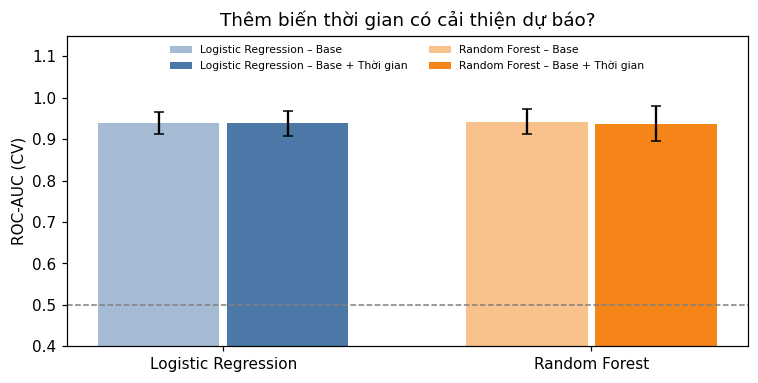

In [11]:
def nb_test(delta, n_test_over_train=0.25):
    # t-test chuẩn hóa lấy mẫu lặp (Nadeau & Bengio, 2003)
    k = len(delta); var = np.var(delta, ddof=1)
    t = np.mean(delta) / math.sqrt((1/k + n_test_over_train) * var)
    return t, 2 * (1 - stats.t.cdf(abs(t), df=k - 1))

rows = []
for mname in ["Logistic Regression", "Random Forest"]:
    a = R[(R["Mô hình"] == mname) & (R["Bộ biến"] == "Base")].sort_values("fold")
    b = R[(R["Mô hình"] == mname) & (R["Bộ biến"] == "Base + Thời gian")].sort_values("fold")
    for met in ["ROC-AUC", "PR-AUC", "Recall@5%"]:
        d = b[met].values - a[met].values
        t, p = nb_test(d)
        rows.append({"Mô hình": mname, "Chỉ số": met, "Δ (có thời gian − Base)": d.mean(), "t": t, "p (Nadeau–Bengio)": p})
delta_tab = pd.DataFrame(rows)
print(delta_tab.round(4).to_string(index=False))

pd_ = np.array(perm_drop)
t_p, p_p = stats.ttest_1samp(pd_, 0)
print(f"\nPermutation importance của nhóm biến thời gian (RF): ΔAUC khi xáo trộn = {pd_.mean():+.4f} "
      f"(SD {pd_.std(ddof=1):.4f}), p≈{p_p:.3f}  [các fold không độc lập nên p chỉ mang tính tham khảo]")

AUC_RF = R[(R["Mô hình"] == "Random Forest") & (R["Bộ biến"] == "Base + Thời gian")]["ROC-AUC"].mean()
AUC_LR = R[(R["Mô hình"] == "Logistic Regression") & (R["Bộ biến"] == "Base + Thời gian")]["ROC-AUC"].mean()
D_RF = delta_tab[(delta_tab["Mô hình"] == "Random Forest") & (delta_tab["Chỉ số"] == "ROC-AUC")].iloc[0]
D_LR = delta_tab[(delta_tab["Mô hình"] == "Logistic Regression") & (delta_tab["Chỉ số"] == "ROC-AUC")].iloc[0]

fig, ax = plt.subplots(figsize=(7, 3.6))
for i, (mname, col) in enumerate([("Logistic Regression", "#4C78A8"), ("Random Forest", "#F58518")]):
    for j, setname in enumerate(["Base", "Base + Thời gian"]):
        v = R[(R["Mô hình"] == mname) & (R["Bộ biến"] == setname)]["ROC-AUC"]
        ax.bar(i + (j - .5) * 0.35, v.mean(), 0.33, yerr=v.std(), color=col, alpha=1 if j else .5, capsize=3,
               label=f"{mname} – {setname}")
ax.axhline(.5, color="gray", ls="--", lw=1)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Logistic Regression", "Random Forest"])
ax.set_ylabel("ROC-AUC (CV)"); ax.set_title("Thêm biến thời gian có cải thiện dự báo?")
ax.set_ylim(.4, 1.15); ax.legend(fontsize=7, frameon=False, loc="upper center", ncol=2); plt.tight_layout(); plt.show()

## 6. Kết luận cho RQ1

In [12]:
decision = "KHÔNG bác bỏ H₀" if P_MAIN >= ALPHA else "BÁC BỎ H₀"
print(f"Kiểm định chính (CMH phân tầng theo batch, n = {len(df):,}, {int(df.pos.sum())} video dương tính):")
print(f"  OR Mantel–Haenszel (hành chính vs ngoài giờ) = {OR_MAIN:.2f}, 95% CI {CI_MAIN}, p = {P_MAIN:.3f}  ->  {decision} (α = {ALPHA})")
print(f"Logistic Regression có kiểm soát nhiễu: OR(office) = {OR_LOGIT:.2f}, 95% CI bootstrap {CI_LOGIT}; CI chứa 1: {LOGIT_CI_HAS_1}")
print(f"Khám phá (cần kiểm chứng): cuối tuần OR(MH) = {sens.loc[3, 'OR MH']:.2f}, CMH p = {sens.loc[3, 'CMH p']:.4f}; trên nửa kiểm chứng: OR = {REP_VALID_WE_OR:.2f}, p = {REP_VALID_WE_P:.3f}.")
print(f"Khung đỉnh chọn từ nửa khám phá ({REP_PEAK}): trên nửa kiểm chứng OR = {REP_VALID_PEAK_OR:.2f}, p = {REP_VALID_PEAK_P:.3f}.")
print(f"Dự báo: ROC-AUC (có thời gian) LR = {AUC_LR:.3f}, RF = {AUC_RF:.3f}; "
      f"ΔAUC do thêm biến thời gian: LR {D_LR['Δ (có thời gian − Base)']:+.4f} (p={D_LR['p (Nadeau–Bengio)']:.2f}), "
      f"RF {D_RF['Δ (có thời gian − Base)']:+.4f} (p={D_RF['p (Nadeau–Bengio)']:.2f})")
print(f"Sức mạnh: chỉ phát hiện được OR ≥ {mde_up:.1f} (hoặc ≤ {mde_dn:.2f}) với power 80%.")

Kiểm định chính (CMH phân tầng theo batch, n = 11,531, 46 video dương tính):
  OR Mantel–Haenszel (hành chính vs ngoài giờ) = 0.80, 95% CI 0.38–1.66, p = 0.667  ->  KHÔNG bác bỏ H₀ (α = 0.05)
Logistic Regression có kiểm soát nhiễu: OR(office) = 0.80, 95% CI bootstrap 0.38–2.11; CI chứa 1: Có
Khám phá (cần kiểm chứng): cuối tuần OR(MH) = 3.29, CMH p = 0.0002; trên nửa kiểm chứng: OR = 3.77, p = 0.022.
Khung đỉnh chọn từ nửa khám phá (15–18h): trên nửa kiểm chứng OR = 1.47, p = 0.710.
Dự báo: ROC-AUC (có thời gian) LR = 0.938, RF = 0.938; ΔAUC do thêm biến thời gian: LR -0.0007 (p=0.92), RF -0.0044 (p=0.69)
Sức mạnh: chỉ phát hiện được OR ≥ 2.2 (hoặc ≤ 0.18) với power 80%.


**Cách diễn giải (đối chiếu với kết quả chạy ở trên):**

1. **Kiểm định chính.** Nếu p (CMH) ≥ 0,05 và khoảng tin cậy của OR chứa 1 → *chưa đủ bằng chứng để bác bỏ H₀*: dữ liệu VN hiện có không cho thấy khung giờ hành chính (T2–T6, 8–17h) khác khung giờ nghỉ ngơi về khả năng lọt Trending.
2. **Sức mạnh thống kê.** Chỉ có 46 video dương tính, kiểm định chỉ đủ nhạy với khác biệt lớn (xem mục power). "Không bác bỏ H₀" **không có nghĩa** là "chứng minh H₀ đúng"; chỉ nên kết luận *không phát hiện ảnh hưởng đủ lớn*.
3. **Biến kết quả** là "được quan sát trên chart", có thể bỏ sót khi monitor tắt. Sai lệch này nhiều khả năng không phụ thuộc khung giờ nên kéo kết quả về phía OR = 1.
4. **Mẫu hình khám phá.** Chỉ coi một mẫu hình tìm sau khi nhìn dữ liệu là *giả thuyết mới* nếu nó lặp lại ở nửa kiểm chứng. Khung giờ "đỉnh" chọn từ nửa khám phá nếu không lặp lại thì **không** được báo cáo như "giờ vàng". Tín hiệu "cuối tuần" cần được diễn giải thận trọng vì dựa trên rất ít video dương tính (khoảng tin cậy rộng) và chênh lệch giữa OR thô với OR phân tầng cho thấy kết quả nhạy với cách chia batch.
5. **Mô hình dự báo.** AUC cao (~0,94) chủ yếu đến từ `log_views` tại T0 (video đã nổi sẵn thì dễ lên chart), không phải từ thời điểm đăng. Điều quan trọng cho RQ1 là ΔAUC khi *thêm* biến thời gian, không phải AUC tuyệt đối.
6. **Mối liên hệ, không phải nhân quả.** Các kênh trong mẫu đến từ danh sách kênh nền (đã từng lên chart) nên kết quả không đại diện cho mọi video YouTube.
7. **Không dùng** bộ so sánh "mostPopular vs control" hay tập con có nhãn rõ ràng để suy luận về RQ1, vì cách lấy mẫu và việc nhãn âm/dương đến từ các batch khác nhau làm sai lệch tỷ lệ. Chi-square thô giữa 8 khung giờ ở mục 3 cũng chưa phân tầng theo batch, chỉ dùng để mô tả.